Dimensiunea volumului RMN 3D (Lățime, Înălțime, Număr felii): (128, 96, 24)


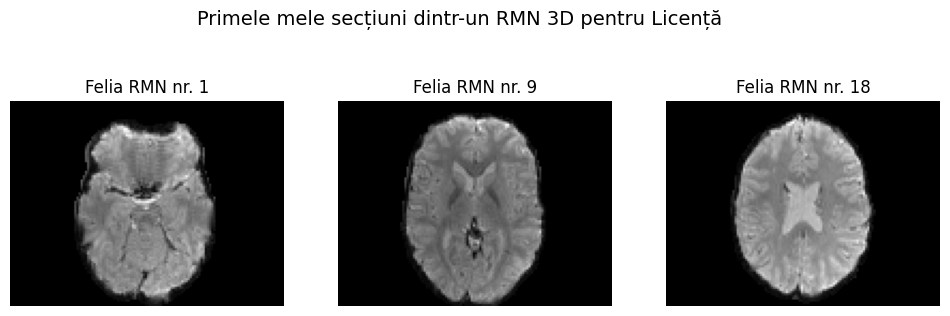

In [ ]:
import os
import nibabel as nib #biblioteca medicala
from nibabel.testing import data_path
import numpy as np #pentru a lucra cu matricele mari de numere
import matplotlib.pyplot as plt

# 1. Încarc un volum RMN 3D de test din biblioteca medicala
#Localizează fișierul de test inclus în biblioteca NiBabel
#și îl încarcă în memorie cu ajutorul funcției nib.load()
cale_rmn = os.path.join(data_path, 'example4d.nii.gz')
fisier_rmn = nib.load(cale_rmn)

# 2. Extragem matricea de date 3D a creierului
volum_creier = fisier_rmn.get_fdata()[:, :, :, 0] #Am transformat fișierul medical într-o matrice uriașă de numere

print(f"Dimensiunea volumului RMN 3D (Lățime, Înălțime, Număr felii): {volum_creier.shape}")

# 3. Afișăm 3 secțiuni (felii) diferite din creier
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
felii_de_afisat = [1, 9, 18]
#1-baza craniului
#12-mijlocul creierului, unde se văd ventriculii
#aproape de vârful capului

for i, nr_felie in enumerate(felii_de_afisat):
    axes[i].imshow(volum_creier[:, :, nr_felie].T, cmap='gray', origin='lower')
    axes[i].set_title(f"Felia RMN nr. {nr_felie}")
    axes[i].axis('off')

plt.suptitle("Primele mele secțiuni dintr-un RMN 3D pentru Licență", fontsize=14)
plt.show()

# 128 96 24 dimensiunea volumului 3D
#128 pixeli lățime,
#96 pixeli înălțime,
#24 reprezintă numărul total de felii (secțiuni) pe axa verticală,
#de la baza creierului până în creștet.

In [5]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("rmn")

print("Tokenul a fost încărcat din Secrets.")

Tokenul a fost încărcat din Secrets.


In [6]:
# 1. Descărcăm baza de date de pe Kaggle folosind comanda oficială API
!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset

# 2. O dezarhivăm automat într-un folder pe serverul Google Colab
import zipfile
with zipfile.ZipFile('brain-tumor-mri-dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('baza_de_date_tumori')

print("Baza de date a fost descărcată și dezarhivată cu succes!")

Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:04<00:00, 35.9MB/s]

Baza de date a fost descărcată și dezarhivată cu succes!


--- STATISTICA BAZEI DE DATE ---
Clasa 'meningioma': 1400 poze de Antrenament | 400 poze de Testare
Clasa 'glioma': 1400 poze de Antrenament | 400 poze de Testare
Clasa 'notumor': 1400 poze de Antrenament | 400 poze de Testare
Clasa 'pituitary': 1400 poze de Antrenament | 400 poze de Testare

Total poze Training: 5600
Total poze Testing: 1600


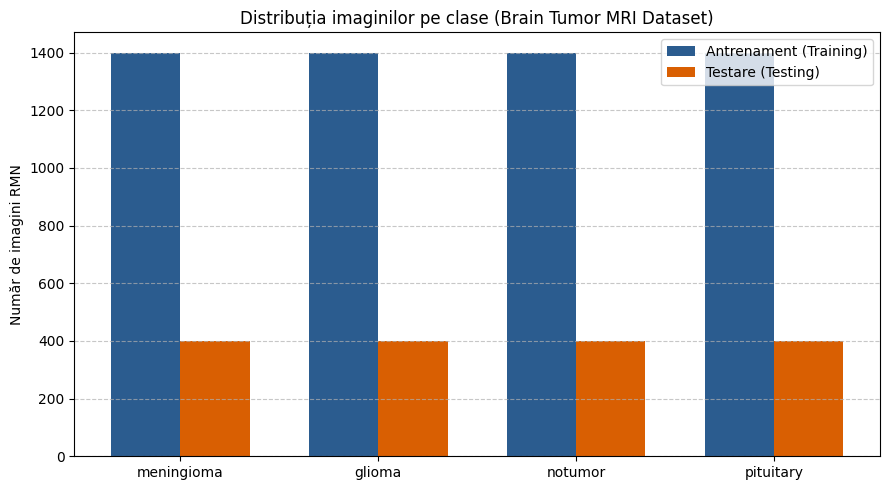

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np

cale_training = os.path.join('baza_de_date_tumori', 'Training')
cale_testing = os.path.join('baza_de_date_tumori', 'Testing')

clase = os.listdir(cale_training)
numar_train = []
numar_test = []

print("--- STATISTICA BAZEI DE DATE ---")
for clasa in clase:
    n_tr = len(os.listdir(os.path.join(cale_training, clasa)))
    n_te = len(os.listdir(os.path.join(cale_testing, clasa)))
    numar_train.append(n_tr)
    numar_test.append(n_te)
    print(f"Clasa '{clasa}': {n_tr} poze de Antrenament | {n_te} poze de Testare")

print(f"\nTotal poze Training: {sum(numar_train)}")
print(f"Total poze Testing: {sum(numar_test)}")

# Desenăm graficul oficial pentru lucrarea de licență
x = np.arange(len(clase))
latime = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - latime/2, numar_train, latime, label='Antrenament (Training)', color='#2b5c8f')
ax.bar(x + latime/2, numar_test, latime, label='Testare (Testing)', color='#d95f02')

ax.set_ylabel('Număr de imagini RMN')
ax.set_title('Distribuția imaginilor pe clase (Brain Tumor MRI Dataset)')
ax.set_xticks(x)
ax.set_xticklabels(clase)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('distributie_clase_licenta.png', dpi=300)
plt.show()

Maparea claselor în cifre pentru rețeaua neuronală: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Număr pachete (batches) de antrenament: 175 (câte 32 poze/pachet)
Dimensiunea matematică a unui pachet (Batch Shape): torch.Size([32, 3, 224, 224])



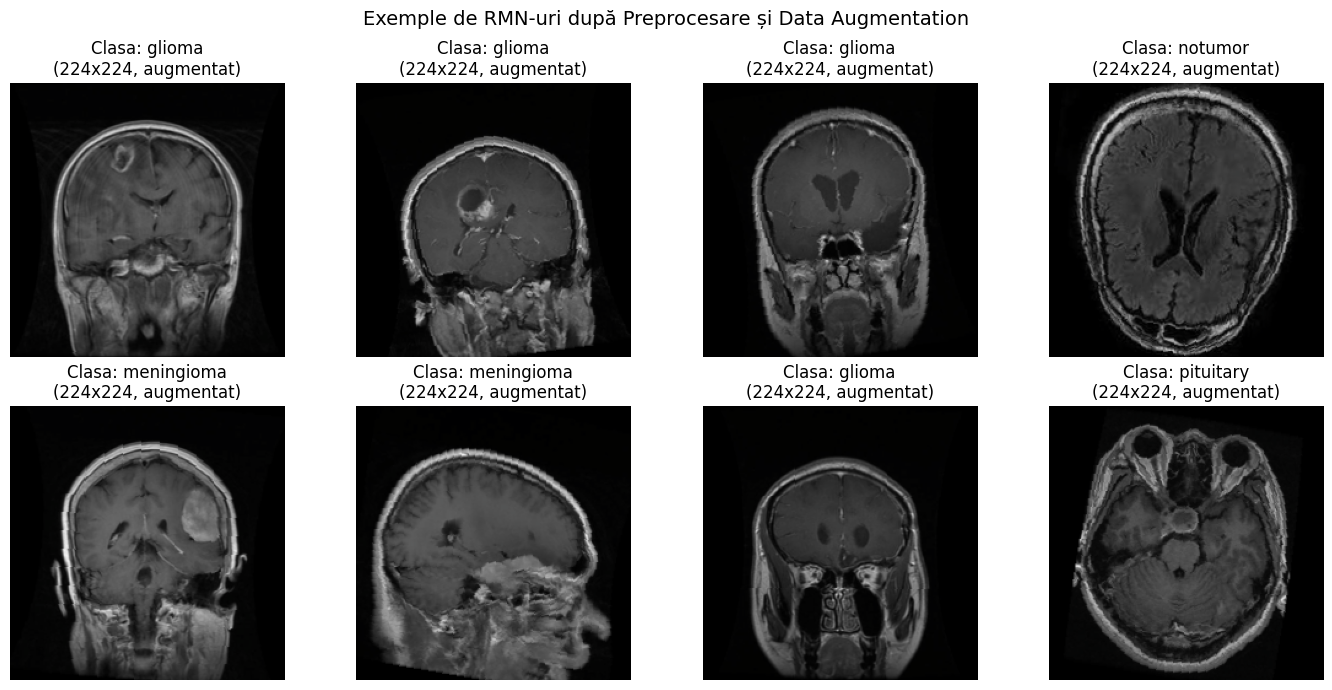

In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 1. Regulile de transformare pentru ANTRENAMENT (cu Data Augmentation)
transformari_train = transforms.Compose([
    transforms.Resize((224, 224)),             # Aducem toate RMN-urile la 224x224 pixeli
    transforms.RandomHorizontalFlip(p=0.5),    # Oglindire orizontală (50% șanse)
    transforms.RandomRotation(degrees=10),     # Rotire ușoară între -10 și +10 grade
    transforms.ToTensor(),                     # Transformare în matrice numerică (Tensor)
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Regulile pentru TESTARE (fără rotiri, doar redimensionare și normalizare)
transformari_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3. Încărcăm seturile de date și creăm benzile rulante (DataLoaders) cu pachete de 32 poze
dataset_train = datasets.ImageFolder(root=cale_training, transform=transformari_train)
dataset_test = datasets.ImageFolder(root=cale_testing, transform=transformari_test)

loader_train = DataLoader(dataset_train, batch_size=32, shuffle=True)
loader_test = DataLoader(dataset_test, batch_size=32, shuffle=False)

print(f"Maparea claselor în cifre pentru rețeaua neuronală: {dataset_train.class_to_idx}")
print(f"Număr pachete (batches) de antrenament: {len(loader_train)} (câte 32 poze/pachet)")

# 4. Scoatem un pachet de probă și afișăm 8 RMN-uri gata preprocesate
imagini_batch, etichete_batch = next(iter(loader_train))
print(f"Dimensiunea matematică a unui pachet (Batch Shape): {imagini_batch.shape}\n")

def denormalizeaza(tensor_img):
    img = tensor_img.numpy().transpose((1, 2, 0))
    img = np.array([0.229, 0.224, 0.225]) * img + np.array([0.485, 0.456, 0.406])
    return np.clip(img, 0, 1)

nume_clase = dataset_train.classes
plt.figure(figsize=(14, 7))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(denormalizeaza(imagini_batch[i]))
    plt.title(f"Clasa: {nume_clase[etichete_batch[i]]}\n(224x224, augmentat)")
    plt.axis('off')

plt.suptitle("Exemple de RMN-uri după Preprocesare și Data Augmentation", fontsize=14)
plt.tight_layout()
plt.savefig('rmn_preprocesate_licenta.png', dpi=300)
plt.show()

In [ ]:
import os

# Verificăm ce foldere există în interiorul directorului dezarhivat
cale_folder = 'baza_de_date_tumori'
print("Conținutul folderului:", os.listdir(cale_folder))

# De obicei, datasetul are un subfolder numit 'Brain Tumor MRI Dataset' sau direct folderele pe clase
# Hai să listăm conținutul din adâncime dacă e cazul
continut = os.listdir(cale_folder)
print("Subfoldere:", continut)

Conținutul folderului: ['Training', 'Testing']
Subfoldere: ['Training', 'Testing']


Clasele de tumori disponibile în dataset: ['pituitary', 'glioma', 'meningioma', 'notumor']


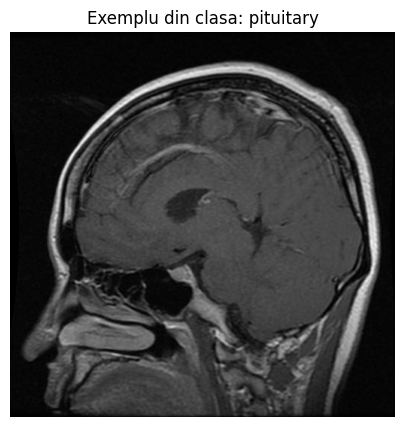

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# 1. Vedem clasele (categoriile) de tumori din setul de antrenament
cale_training = os.path.join('baza_de_date_tumori', 'Training')
clase = os.listdir(cale_training)
print(f"Clasele de tumori disponibile în dataset: {clase}")

# 2. Alegem prima clasă și luăm o imagine din ea
prima_clasa = clase[0]
cale_clasa = os.path.join(cale_training, prima_clasa)
nume_poza = os.listdir(cale_clasa)[0]
cale_completă_poza = os.path.join(cale_clasa, nume_poza)

# 3. Deschidem și afișăm imaginea RMN 2D
imagine = Image.open(cale_completă_poza)
plt.figure(figsize=(5, 5))
plt.imshow(imagine, cmap='gray')
plt.title(elsk := f"Exemplu din clasa: {prima_clasa}")
plt.axis('off')
plt.show()

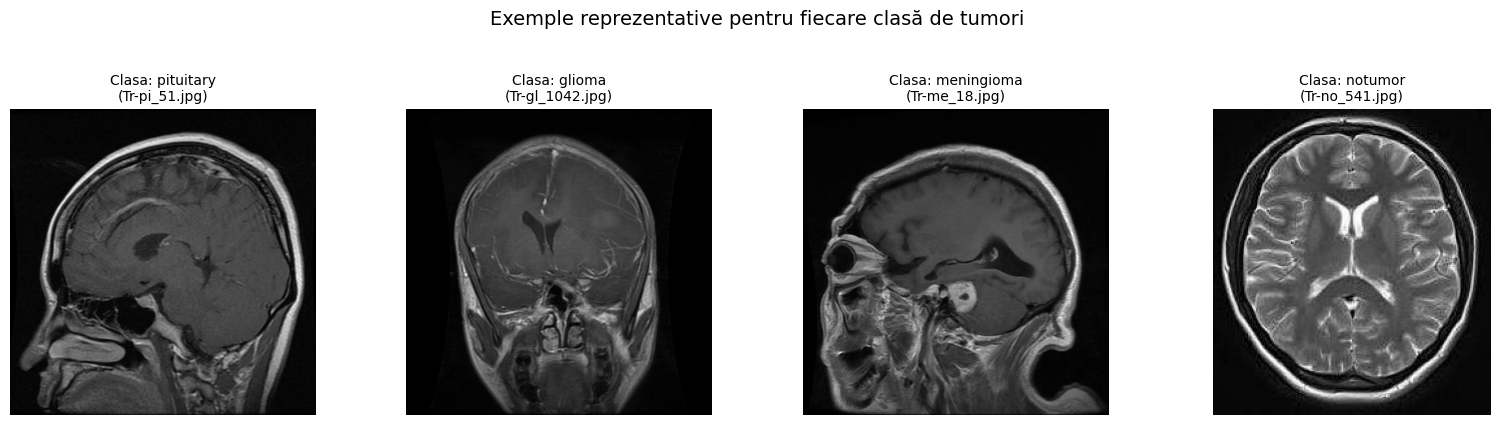

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# Definim clasele identificate anterior
clase_tumori = ['pituitary', 'glioma', 'meningioma', 'notumor']
cale_training = os.path.join('baza_de_date_tumori', 'Training')

# Pregătim figura cu 4 sub-grafice pe un singur rând
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i, clasa in enumerate(clase_tumori):
    cale_clasa = os.path.join(cale_training, clasa)

    # Selectăm prima imagine din folderul clasei respective
    imagini_clasa = os.listdir(cale_clasa)
    nume_imagine = imagini_clasa[0]
    cale_completa = os.path.join(cale_clasa, nume_imagine)

    # Deschidem și afișăm imaginea
    img = Image.open(cale_completa)
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Clasa: {clasa}\n({nume_imagine})", fontsize=10)
    axes[i].axis('off')

plt.suptitle("Exemple reprezentative pentru fiecare clasă de tumori", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

In [ ]:
import os

cale_baza = 'baza_de_date_tumori'
seturi = ['Training', 'Testing']

for set_nume in seturi:
    print(f"--- Setul de {set_nume} ---")
    cale_set = os.path.join(cale_baza, set_nume)
    clase = sorted(os.listdir(cale_set))

    total_imagini = 0
    for clasa in clase:
        cale_clasa = os.path.join(cale_set, clasa)
        nr_imagini = len(os.listdir(cale_clasa))
        print(f"  Clasa '{clasa}': {nr_imagini} imagini")
        total_imagini += nr_imagini

    print(f"Total imagini în {set_nume}: {total_imagini}\n")

--- Setul de Training ---
  Clasa 'glioma': 1400 imagini
  Clasa 'meningioma': 1400 imagini
  Clasa 'notumor': 1400 imagini
  Clasa 'pituitary': 1400 imagini
Total imagini în Training: 5600

--- Setul de Testing ---
  Clasa 'glioma': 400 imagini
  Clasa 'meningioma': 400 imagini
  Clasa 'notumor': 400 imagini
  Clasa 'pituitary': 400 imagini
Total imagini în Testing: 1600



In [ ]:
import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory

# Definim parametrii de bază pentru preprocesare
BATCH_SIZE = 32
IMG_SIZE = (150, 150) # Redimensionăm toate imaginile la 150x150

cale_training = 'baza_de_date_tumori/Training'
cale_testing = 'baza_de_date_tumori/Testing'

print("Se încarcă setul de Antrenare...")
train_ds = image_dataset_from_directory(
    cale_training,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical', # Returnează etichete de tip one-hot encoding pentru cele 4 clase
    shuffle=True
)

print("\nSe încarcă setul de Testare...")
test_ds = image_dataset_from_directory(
    cale_testing,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

# Aplicăm normalizarea (scalarea pixelilor din [0, 255] în [0, 1])
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y))

print("\nPreprocesarea inițială a fost configurată cu succes!")

Se încarcă setul de Antrenare...
Found 5600 files belonging to 4 classes.

Se încarcă setul de Testare...
Found 1600 files belonging to 4 classes.

Preprocesarea inițială a fost configurată cu succes!
